# 02 · Análise exploratória

Antes de treinar qualquer modelo, precisamos de **conhecer os dados**. Esta etapa responde a perguntas simples, mas que orientam todas as decisões seguintes:

1. Como se distribuem os preços?
2. Quanto pesa a **localização** (freguesia)?
3. Qual a relação entre **área** e **preço**?
4. O **estado** do imóvel faz diferença?
5. Os **extras** (piscina, terraço, estacionamento…) valorizam a casa?
6. Que peso têm as **casas de luxo**?

| | |
|---|---|
| **Entrada** | `data/processed/dados_limpos.csv` |
| **Saída** | gráficos em `reports/figures/` |

> Lembrete: o texto explica *o quê* e *porquê*; os comentários (`#`) dentro do código explicam *como*.
>
> Usamos quase sempre a **mediana** (o valor do meio) em vez da média. A média é "puxada" por poucas casas muito caras; a mediana representa melhor a casa típica.

## 0. Preparação

In [1]:
import sys
from pathlib import Path

import numpy as np                  # cálculos numéricos (logaritmos, correlações)
import pandas as pd                 # tabelas de dados
import matplotlib.pyplot as plt     # gráficos

# Procurar a pasta do projeto: começamos na pasta atual (Path.cwd()) e subimos
# pasta a pasta (.parent) até encontrar a pasta 'src'. Assim o notebook funciona
# quer seja aberto a partir da pasta 'notebooks/', quer a partir da raiz do projeto.
RAIZ_PROJETO = Path.cwd()
while not (RAIZ_PROJETO / "src").is_dir() and RAIZ_PROJETO != RAIZ_PROJETO.parent:
    RAIZ_PROJETO = RAIZ_PROJETO.parent
sys.path.append(str(RAIZ_PROJETO))   # agora o Python consegue encontrar o módulo 'src'
from src.utils import (FICHEIRO_LIMPO, PRECO_MAX, NOMES_ESTADO, AZUL, TEXTO, TEXTO_2,
                       aplicar_estilo, euros, euros_curto, sem_rotulo, guardar_figura,
                       formatar_euros, num_pt)

aplicar_estilo()                    # aplica as cores e o estilo comuns a todos os gráficos
df = pd.read_csv(FICHEIRO_LIMPO)    # lê os dados limpos criados no notebook 01
print(f"{len(df)} apartamentos à venda em Lisboa")

1623 apartamentos à venda em Lisboa


## 1. Visão geral

Os percentis ajudam a perceber a "forma" dos dados: o percentil 10% é o valor abaixo do qual estão 10% das casas; o 90% é o valor abaixo do qual estão 90%.

In [2]:
# describe() com percentis personalizados: 10%, 25%, 50% (mediana), 75% e 90%
resumo = df[["preco", "area_m2", "preco_m2"]].describe(percentiles=[.1, .25, .5, .75, .9])
resumo.columns = ["Preço (€)", "Área (m²)", "Preço/m² (€)"]
resumo.round(0)

,Preço (€),Área (m²),Preço/m² (€)
count,1623.0,1623.0,1623.0
mean,979538.0,135.0,7202.0
std,790785.0,79.0,2429.0
min,139000.0,26.0,2135.0
10%,385000.0,58.0,4606.0
25%,527500.0,82.0,5564.0
50%,735000.0,116.0,6805.0
75%,1152500.0,165.0,8333.0
90%,1808000.0,234.0,10311.0
max,10000000.0,600.0,25750.0


## 2. Distribuição dos preços

Os preços das casas têm sempre uma **"cauda longa"**: muitas casas num intervalo intermédio e poucas muito caras. Num gráfico normal, as casas caras "esmagam" o resto.

Por isso usamos uma **escala logarítmica** no eixo horizontal: cada marca representa uma multiplicação (200 mil → 400 mil → 1 M → 2 M), o que "estica" os valores baixos e "comprime" os altos.

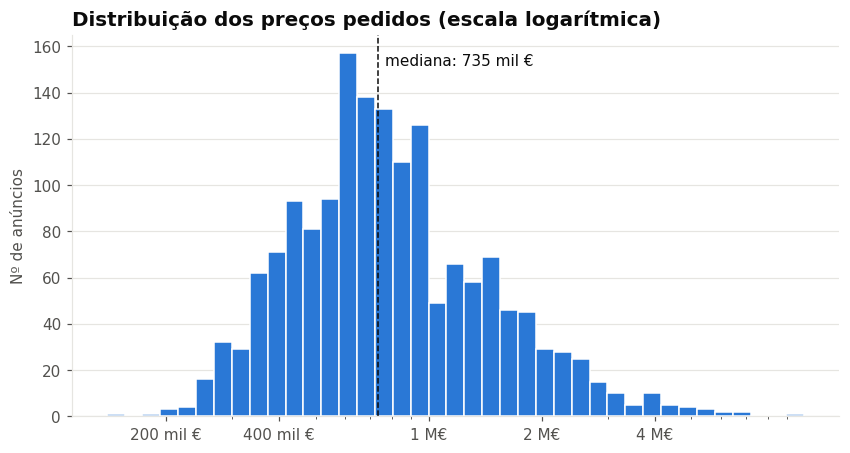

In [3]:
# plt.subplots cria uma "figura" (fig) com uma área de desenho (ax).
# figsize = (largura, altura) em polegadas.
fig, ax = plt.subplots(figsize=(9, 4.5))

# Um histograma agrupa os preços em intervalos ("barras") e conta quantas casas
# caem em cada um. np.logspace cria 40 intervalos igualmente espaçados em escala
# logarítmica, entre o preço mínimo e o máximo.
intervalos = np.logspace(np.log10(df["preco"].min()), np.log10(df["preco"].max()), 40)
ax.hist(df["preco"], bins=intervalos, color=AZUL, edgecolor="white", linewidth=1)

# Eixo horizontal em escala logarítmica, com marcas em valores "redondos"
ax.set_xscale("log")
ax.set_xticks([200e3, 400e3, 1e6, 2e6, 4e6])
ax.xaxis.set_major_formatter(euros_curto)
ax.xaxis.set_minor_formatter(sem_rotulo)

# Linha vertical tracejada na mediana, com uma etiqueta ao lado
mediana = df["preco"].median()
ax.axvline(mediana, color=TEXTO, linewidth=1, linestyle="--")
ax.text(mediana * 1.04, ax.get_ylim()[1] * 0.92, f"mediana: {mediana/1000:.0f} mil €", color=TEXTO)
ax.set_title("Distribuição dos preços pedidos (escala logarítmica)")
ax.set_ylabel("Nº de anúncios")
ax.grid(axis="x", visible=False)
guardar_figura(fig, "01_distribuicao_precos.png")   # grava em reports/figures/
plt.show()                                          # mostra o gráfico no notebook

**Leitura:** com escala logarítmica a distribuição fica aproximadamente em forma de "sino". É uma pista de que **modelar o logaritmo do preço** (em vez do preço em euros) vai funcionar melhor — fazemos exatamente isso no notebook 03.

## 3. Preço por m² por freguesia

A localização é, em imobiliário, quase tudo. Comparamos o **preço mediano por m²** de cada freguesia.

Freguesias com **menos de 10 anúncios** ficam de fora do gráfico: com tão poucas casas, a mediana não é fiável.

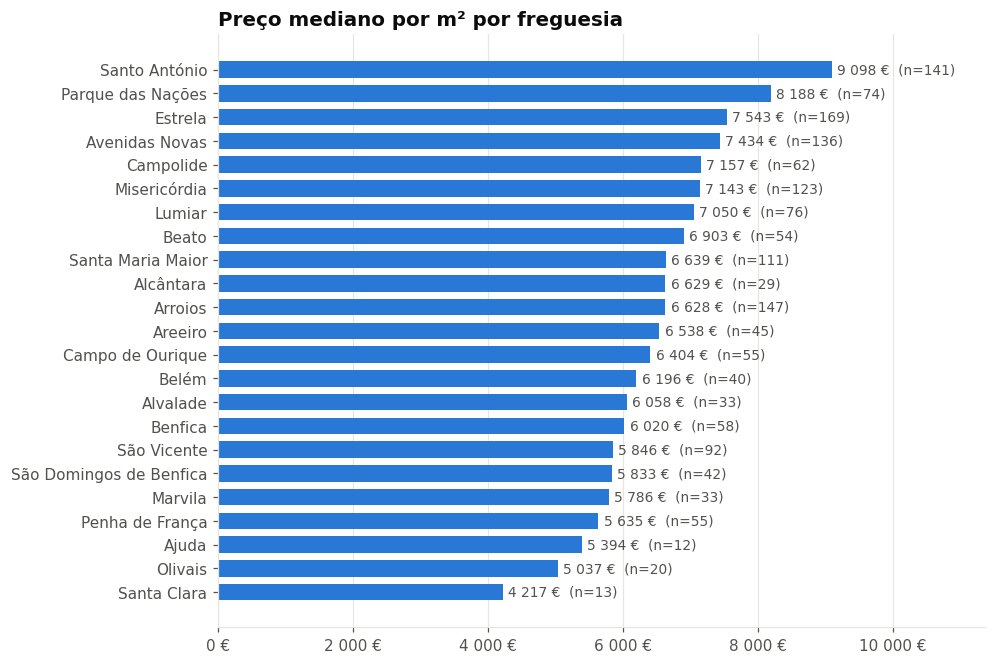

Excluídas por terem menos de 10 anúncios: Carnide


In [4]:
# groupby("freguesia") junta as casas por freguesia (como uma tabela dinâmica no Excel).
# .agg(...) calcula, para cada grupo:
#   preco_m2 = mediana do preço por m²
#   n        = nº de casas (size = contagem)
por_freguesia = (df.groupby("freguesia")
                   .agg(preco_m2=("preco_m2", "median"), n=("preco_m2", "size"))
                   .sort_values("preco_m2"))

# .query("condição") filtra linhas com uma condição escrita em texto
excluidas = por_freguesia.query("n < 10")
por_freguesia = por_freguesia.query("n >= 10")

fig, ax = plt.subplots(figsize=(9, 7))
# barh = barras horizontais (os nomes das freguesias ficam legíveis no eixo vertical)
ax.barh(por_freguesia.index, por_freguesia["preco_m2"], color=AZUL, height=0.7)

# Escrevemos o valor e o nº de casas à frente de cada barra.
# zip junta duas listas par a par; enumerate dá também a posição (i) de cada barra.
for i, (valor, n) in enumerate(zip(por_freguesia["preco_m2"], por_freguesia["n"])):
    ax.text(valor + 80, i, f"{valor:,.0f} €  (n={n})".replace(",", " "),
            va="center", color=TEXTO_2, fontsize=9)
ax.xaxis.set_major_formatter(euros)
ax.set_xlim(0, por_freguesia["preco_m2"].max() * 1.25)
ax.set_title("Preço mediano por m² por freguesia")
ax.grid(axis="y", visible=False)
guardar_figura(fig, "02_preco_m2_freguesia.png")
plt.show()

if len(excluidas):
    print("Excluídas por terem menos de 10 anúncios:", ", ".join(excluidas.index))

In [5]:
# A tabela está ordenada do mais barato para o mais caro:
# a primeira linha ([0]) é a mais barata e a última ([-1]) a mais cara.
# .iloc[posição] acede a um valor pela sua posição na tabela.
mais_cara, mais_barata = por_freguesia.index[-1], por_freguesia.index[0]
racio = por_freguesia["preco_m2"].iloc[-1] / por_freguesia["preco_m2"].iloc[0]
print(f"Mais cara:   {mais_cara} ({por_freguesia['preco_m2'].iloc[-1]:,.0f} €/m²)".replace(",", " "))
print(f"Mais barata: {mais_barata} ({por_freguesia['preco_m2'].iloc[0]:,.0f} €/m²)".replace(",", " "))
print(f"O m² na freguesia mais cara custa {num_pt(racio)}× o da mais barata.")

Mais cara:   Santo António (9 098 €/m²)
Mais barata: Santa Clara (4 217 €/m²)
O m² na freguesia mais cara custa 2,2× o da mais barata.


**Leitura:** a diferença entre freguesias é enorme — o mesmo m² pode custar mais do dobro conforme a zona. A localização vai ser uma das variáveis mais importantes do modelo.

Repara também que algumas freguesias têm **poucos anúncios** (n pequeno). Nessas zonas, as previsões do modelo vão ser menos fiáveis.

## 4. Área vs preço

Cada ponto é um anúncio. Se os pontos formassem uma linha perfeita, a área explicaria tudo. A **largura da nuvem** mostra o que a área sozinha **não** explica (localização, estado, extras…).

Usamos escala logarítmica nos dois eixos, pelas mesmas razões do ponto 2.

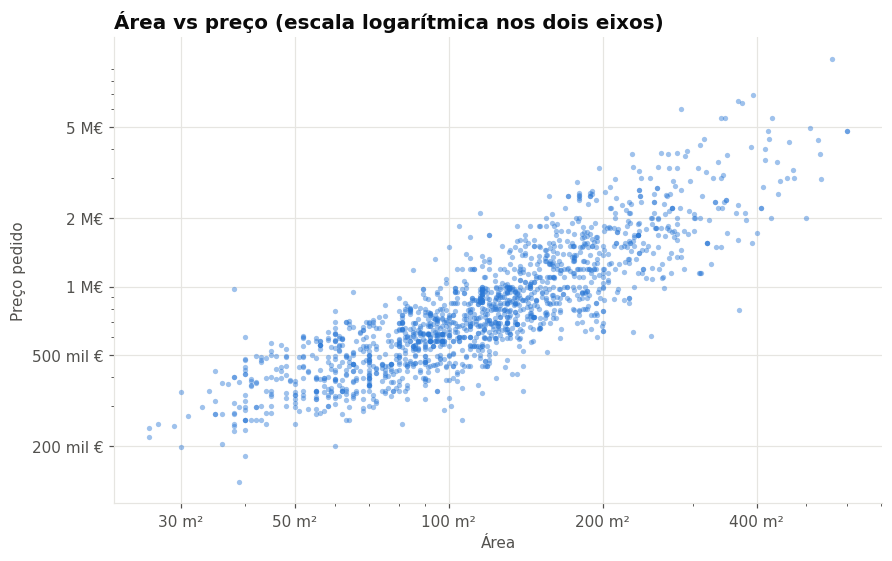

Correlação entre log(área) e log(preço): 0,85  (1 = relação perfeita)


In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))

# scatter = gráfico de pontos. s = tamanho dos pontos; alpha = transparência
# (0,45 → pontos semitransparentes, para se ver onde há muitas casas sobrepostas)
ax.scatter(df["area_m2"], df["preco"], s=12, color=AZUL, alpha=0.45, linewidths=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([30, 50, 100, 200, 400])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f} m²"))
ax.xaxis.set_minor_formatter(sem_rotulo)
ax.set_yticks([200e3, 500e3, 1e6, 2e6, 5e6])
ax.yaxis.set_major_formatter(euros_curto)
ax.yaxis.set_minor_formatter(sem_rotulo)
ax.set_title("Área vs preço (escala logarítmica nos dois eixos)")
ax.set_xlabel("Área"); ax.set_ylabel("Preço pedido")
guardar_figura(fig, "03_area_vs_preco.png")
plt.show()

# A correlação mede quão "alinhados" estão dois valores: 1 = relação perfeita,
# 0 = nenhuma relação. Calculamo-la em escala logarítmica, como no gráfico.
correlacao = np.corrcoef(np.log(df["area_m2"]), np.log(df["preco"]))[0, 1]
print(f"Correlação entre log(área) e log(preço): {num_pt(correlacao, 2)}  (1 = relação perfeita)")

**Leitura:** a relação é **forte** (correlação próxima de 0,85): casas maiores são mais caras, como esperado. Mas para a mesma área há casas com o dobro do preço de outras — é essa diferença que o modelo tem de aprender a explicar com as restantes variáveis.

## 5. Estado do imóvel

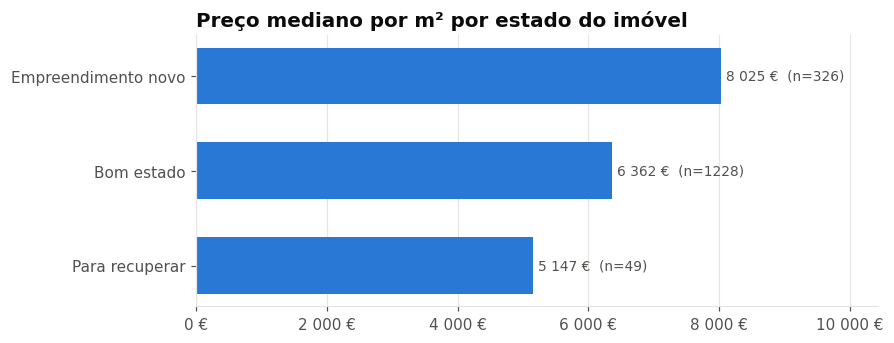

Um empreendimento novo pede, por m², mais 26% do que um imóvel em bom estado.


In [7]:
# 1) traduzimos o estado para português (os vazios passam a "desconhecido")
# 2) agrupamos por estado e calculamos a mediana do preço/m² e o nº de casas
# 3) .reindex(...) põe as linhas pela ordem que queremos no gráfico
por_estado = (df.assign(estado=df["estado"].fillna("desconhecido").map(NOMES_ESTADO))
                .groupby("estado")
                .agg(preco_m2=("preco_m2", "median"), n=("preco_m2", "size"))
                .reindex(["Para recuperar", "Bom estado", "Empreendimento novo"]))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(por_estado.index, por_estado["preco_m2"], color=AZUL, height=0.6)
for i, (valor, n) in enumerate(zip(por_estado["preco_m2"], por_estado["n"])):
    ax.text(valor + 80, i, f"{valor:,.0f} €  (n={n})".replace(",", " "),
            va="center", color=TEXTO_2, fontsize=9)
ax.xaxis.set_major_formatter(euros)
ax.set_xlim(0, por_estado["preco_m2"].max() * 1.3)
ax.set_title("Preço mediano por m² por estado do imóvel")
ax.grid(axis="y", visible=False)
guardar_figura(fig, "04_preco_m2_estado.png")
plt.show()

# .loc[linha, coluna] acede a um valor pelo nome da linha e da coluna.
# Dividir os dois valores e subtrair 1 dá a diferença em percentagem.
premio = por_estado.loc["Empreendimento novo", "preco_m2"] / por_estado.loc["Bom estado", "preco_m2"] - 1
print(f"Um empreendimento novo pede, por m², mais {premio:.0%} do que um imóvel em bom estado.")

**Leitura:** o estado tem um efeito claro e na direção esperada: **para recuperar < bom estado < novo**. Atenção que só há ~50 casas "para recuperar", por isso esse valor é menos preciso.

## 6. Os extras valorizam a casa?

Para cada extra, comparamos o preço mediano por m² entre as casas que **têm**, as que **não têm** e aquelas em que **não sabemos** (o anunciante não indicou).

In [8]:
EXTRAS = {"piscina": "Piscina", "terraco": "Terraço", "jardim": "Jardim",
          "estacionamento": "Estacionamento", "elevador": "Elevador",
          "ar_condicionado": "Ar condicionado", "arrecadacao": "Arrecadação"}

linhas = []   # aqui vamos guardar uma linha de resultados por extra

# .items() percorre o dicionário, dando a chave (coluna) e o valor (nome) de cada par
for coluna, nome in EXTRAS.items():
    # Classificamos cada casa em 3 grupos: "tem" (1), "não tem" (0) ou "não indicado" (vazio)
    grupo = df[coluna].map({1: "tem", 0: "não tem"}).fillna("não indicado")
    # Mediana do preço/m² em cada grupo, e nº de casas em cada grupo
    medianas = df.groupby(grupo)["preco_m2"].median()
    contagens = grupo.value_counts()
    linhas.append({
        "extra": nome,
        "€/m² — tem": medianas.get("tem"),
        "€/m² — não tem": medianas.get("não tem"),
        "€/m² — não indicado": medianas.get("não indicado"),
        "diferença (tem vs não tem)": medianas.get("tem") / medianas.get("não tem") - 1,
        "% não indicado": contagens.get("não indicado", 0) / len(df),
    })

# Transformamos a lista de resultados numa tabela, ordenada pela diferença
extras = pd.DataFrame(linhas).set_index("extra").sort_values("diferença (tem vs não tem)", ascending=False)

# .style.format(...) só muda a APRESENTAÇÃO dos números (euros, percentagens),
# não os valores em si. na_rep="—" mostra um traço onde não há valor.
extras.style.format({
    "€/m² — tem": formatar_euros, "€/m² — não tem": formatar_euros, "€/m² — não indicado": formatar_euros,
    "diferença (tem vs não tem)": "{:+.0%}", "% não indicado": "{:.0%}",
}, na_rep="—")

,€/m² — tem,€/m² — não tem,€/m² — não indicado,diferença (tem vs não tem),% não indicado
extra,,,,,
Piscina,8 567 €,6 328 €,6 850 €,+35%,45%
Elevador,7 410 €,5 957 €,5 836 €,+24%,6%
Estacionamento,7 647 €,6 184 €,—,+24%,0%
Ar condicionado,7 498 €,6 226 €,6 221 €,+20%,10%
Jardim,7 342 €,6 538 €,6 748 €,+12%,43%
Arrecadação,7 158 €,6 685 €,6 706 €,+7%,37%
Terraço,7 045 €,6 666 €,6 786 €,+6%,40%


**Leitura:** todos os extras aparecem associados a preços por m² mais altos. **Mas cuidado com a interpretação:** isto **não** prova que a piscina, sozinha, faz subir o preço. Pode acontecer que as casas com piscina sejam, por exemplo, sobretudo **empreendimentos novos** — e que seja isso a puxar o preço. Vamos confirmar:

In [9]:
# Para cada grupo (tem / não tem / não indicado), que % das casas são empreendimentos novos?
grupo_piscina = df["piscina"].map({1: "tem piscina", 0: "não tem piscina"}).fillna("não indicado")
(df.groupby(grupo_piscina)["empreendimento_novo"].mean() * 100).round(0).to_frame("% empreendimentos novos")

,% empreendimentos novos
piscina,
não indicado,23.0
não tem piscina,12.0
tem piscina,50.0


**Leitura:** confirma-se — **cerca de metade das casas com piscina são empreendimentos novos**, contra pouco mais de 10% das que não têm. Parte do "efeito piscina" é, na verdade, o efeito "casa nova". A isto chama-se **correlação ≠ causalidade**.

Repara também na coluna **% não indicado**: para a piscina, o jardim e o terraço, cerca de 40% dos anúncios não dizem nada — o que reduz a informação disponível para o modelo.

O modelo vai ajudar a separar estes efeitos: como "vê" todas as variáveis ao mesmo tempo, consegue perceber quanto valor acrescenta cada extra **depois** de já saber a localização, a área e o estado.

## 7. As casas de luxo

As casas muito caras são **poucas, muito diferentes entre si** e difíceis de prever. Vamos ver quanto pesam nos dados, usando o limite definido em `src/utils.py`.

In [10]:
# luxo é uma coluna True/False: True para as casas acima do limite.
# .sum() conta os True; .mean() dá a proporção de True.
luxo = df["preco"] > PRECO_MAX
print(f"Casas acima de {num_pt(PRECO_MAX/1e6)} M€: {luxo.sum()} ({num_pt(luxo.mean()*100)}% dos anúncios)")
print(f"Preço mediano do luxo:     {num_pt(df.loc[luxo, 'preco'].median()/1e6)} M€")
print(f"Preço mediano das restantes: {df.loc[~luxo, 'preco'].median()/1e3:.0f} mil €")

Casas acima de 2,5 M€: 70 (4,3% dos anúncios)
Preço mediano do luxo:     3,3 M€
Preço mediano das restantes: 710 mil €


**Leitura:** são menos de 5% dos anúncios, mas com preços várias vezes acima da casa típica. Num modelo que aprende a minimizar erros, estas casas têm um peso desproporcionado e "puxam" as previsões das casas normais.

Por isso, no notebook 03 **decidimos focar o modelo no mercado até 2,5 M€** — e confirmamos com um teste que esta decisão reduz o erro nas casas normais.

## Conclusões

1. **Os preços têm uma cauda longa** → vamos modelar o **logaritmo do preço**.
2. **A localização pesa muito**: o preço por m² varia mais do dobro entre freguesias.
3. **A área é o fator individual mais forte** (correlação ~0,85 em escala log).
4. **O estado conta**: um empreendimento novo pede bastante mais por m² do que um imóvel em bom estado.
5. **Os extras estão associados a preços mais altos**, mas em parte porque aparecem em casas novas e zonas caras — o modelo separa estes efeitos.
6. **O luxo é raro e muito diferente** → fica fora do âmbito do modelo.
7. **Limitação:** a amostra são os primeiros resultados de uma pesquisa no portal de anúncios e pode estar inclinada para imóveis mais caros do que o mercado total de Lisboa.

➡️ **Próximo passo:** `03_modelacao.ipynb`